**APLICACION DE UN MODELO DE MACHINE LEARNING DE REGRESION LINEAL**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


En esta actividad usarás el archivo de datos `bigMartSales.csv`.

* `Item_Identifier`: ID de producto único
* `Item_Weight`: Peso del producto
* `Item_Fat_Content`: si el producto es bajo en grasa o no
* `Item_Visibility`: el porcentaje del área de exhibición total de todos los productos en una tienda asignado al producto en particular.
* `Item_Type`: La categoría a la que pertenece el producto.
* `Item_MRP`: Precio de venta máximo (precio de lista) del producto
* `Outlet_Identifier`: ID de tienda única
* `Outlet_Establishment_Year`: El año en que se estableció la tienda.
* `Outlet_Size`: El tamaño de la tienda en términos de superficie cubierta.
* `Outlet_Location_Type`: El tipo de ciudad en la que se encuentra la tienda.
* `Outlet_Type`: si el outlet es solo una tienda de comestibles o algún tipo de supermercado.

* **`Item_Outlet_Sales`**: Ventas del producto en la tienda concreta. Ésta es la variable de resultado que se va a predecir.

In [ ]:
# Librerías para manipulación de datos
import numpy as np
import pandas as pd

# Librerías para visualización
import seaborn as sns
import matplotlib.pyplot as plt


# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer #sirve para rellenar los datos faltantes (imputar)
                    #Cuando tienes datos con valores nulos (NaN), permite remplazarlos con mean, median, most_frecuent, constant)


from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
              #MinMaxScaler, normaliza los datos numericos dentro de un rango [0,1]
                    #ayuda a que los modelos ML funcionen mejor, reduce la influencia de variables con escalas muy diferentes

              #OneHOTEncoder, convierte variables categoricas en una representacion binaria
                    #Algoritmo de ML no entienden texto. Este enconder convierte cada columna Categorica en na BInaria (0 y 1)

# Librerías para la canalización (pipeline)
    #es una forma ordenada de Encadenar pasos de preprocesamiento y modelado, forma que puedas tratar tus datos y entrenar un modelo
    #todo en una sola estructura, sin repetir codigo ni cometer errores por hacer pasos manuales

from sklearn.compose import ColumnTransformer, make_column_selector
      #ColumnTransformer, aplica diferentes transformaciones a diferentes columnas de tu conjunto de datos
          #dado que NO TODAS las columnas necesitan el mismo tratamiento
          #Columnas numericas, se escalan con MinMAxScaler
          #Columnas categoricas se codifican con OneHOtEncoder

      #make_column_selector, selecciona automaticamente columnas numericas o categoricas del DF segun su tipo de datos
          #Para no escribir los nombres de las columnas manualmente. Especialmente util cuando tenemos muchas columnas y
          #queremos seleccionar todas las numericas o todas las categoricas sin necesidad de enlistarlas

from sklearn.pipeline import make_pipeline
      #permite encadenar los pasos secuenciales de transformacion y modelado (Escalado - Codificacion - modelado)
      #Se evita tener que hacer transformaciones por separado y nos asegura que se aplicacn en el orden correcto, tanto al entrenar como al hacer predicciones


# Librerías para la regresión
from sklearn.linear_model import LinearRegression
      #modelo de Regresion Lineal clasico de Scikit-learn
      #ENTRENA UN MODELO DE REGRESION LINEAL PARA PREDECIR VALORES NUMERICOS
      #se utiliza para predecir valores numericos en funcion de una variable o mas variables independientes.
      #Busca una linea recta que mejor se ajuste a los datos

from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score
      #mean_squared_error(MSE), la media de los cuadrados de las diferencias entre los valores reales y los predichos
      #EVALUA EL MODELO MIDIENDO EL ERROR CUADRATICO MEDIO
      #Cuanto mas bajo el MSE, mejor es el modelo
      #tienen las mismas unidades que la variable objetivo al elevar al cuadrado, lo que penaliza los errores

      #Coeficiente de determinacion (r2_score), indica que la proporcion de la varianza en la variable dependiente se puede explciar por las variables independientes
      #EVALUA EL MODELO INDICANDO QUE TAMBIEN EXPLICA LA VARIACION DE LOS DATOS
      #su valor va entre 0 y 1
      #r2_score=1, el modelo predice de manera perfecta
      #r2_scores=0, el modelo no explica nada mejor que una media

Descarga el archivo: `bigMartSales.csv` y guarda, en un dataframe (`sales_df`), todos sus registros.

In [ ]:
sales_df = pd.read_csv('/content/drive/MyDrive/bigMartSales.csv')
sales_df

# Unificar las categorías de contenido de grasa
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

# Crear la característica 'Outlet_Age' (usando 2013 como año de referencia del dataset)
sales_df['Outlet_Age'] = 2013 - sales_df['Outlet_Establishment_Year']
sales_df.drop('Outlet_Establishment_Year', axis=1, inplace=True)

# Actualizar la separación de variables (X e y)
X = sales_df.drop('Item_Outlet_Sales', axis=1)
y = sales_df['Item_Outlet_Sales']

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

ANALISIS DE DATOS

In [ ]:
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Item_Identifier       8523 non-null   object 
 1   Item_Weight           7060 non-null   float64
 2   Item_Fat_Content      8523 non-null   object 
 3   Item_Visibility       8523 non-null   float64
 4   Item_Type             8523 non-null   object 
 5   Item_MRP              8523 non-null   float64
 6   Outlet_Identifier     8523 non-null   object 
 7   Outlet_Size           6113 non-null   object 
 8   Outlet_Location_Type  8523 non-null   object 
 9   Outlet_Type           8523 non-null   object 
 10  Item_Outlet_Sales     8523 non-null   float64
 11  Outlet_Age            8523 non-null   int64  
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [ ]:
# Determinando la cantidad de valores únicos por columna
sales_df.nunique()

,0
Item_Identifier,1559
Item_Weight,415
Item_Fat_Content,2
Item_Visibility,7880
Item_Type,16
Item_MRP,5938
Outlet_Identifier,10
Outlet_Size,3
Outlet_Location_Type,3
Outlet_Type,4


Como las variables `Item_Identifier` y `Outlet_Identifier` son solo variables de ID, asumimos que no tienen ningún poder predictivo para predecir la variable dependiente: `Item_Outlet_Sales`.

In [ ]:
sales_df.drop(['Item_Identifier','Outlet_Identifier'], axis=1, inplace=True)

In [ ]:
# Estadísticas descriptivas de las variables numéricas
sales_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Item_Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item_MRP,8523.0,140.992782,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Item_Outlet_Sales,8523.0,2181.288914,1706.499616,33.290,834.247400,1794.331000,3101.296400,13086.964800
Outlet_Age,8523.0,15.168133,8.371760,4.000,9.000000,14.000000,26.000000,28.000000


In [ ]:
# Estadísticas descriptivas de las variables de texto
sales_df.describe(include = 'object').T

,count,unique,top,freq
Item_Fat_Content,8523,2,Low Fat,5517
Item_Type,8523,16,Fruits and Vegetables,1232
Outlet_Size,6113,3,Medium,2793
Outlet_Location_Type,8523,3,Tier 3,3350
Outlet_Type,8523,4,Supermarket Type1,5577


In [ ]:
# Se hace una lista de variables numéricas y otra de categóricas.
num_cols = sales_df.select_dtypes(include=np.number).columns.tolist()
cat_cols = sales_df.select_dtypes(exclude=np.number).columns.tolist()

In [ ]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(column)
    print(sales_df[column].value_counts())
    print('-' * 50)

Item_Fat_Content
Item_Fat_Content
Low Fat    5517
Regular    3006
Name: count, dtype: int64
--------------------------------------------------
Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64
--------------------------------------------------
Outlet_Size
Outlet_Size
Medium    2793
Small     2388
High       932
Name: count, dtype: int64
--------------------------------------------------
Outlet_Location_Type
Outlet_Location_Type
Tier 3    3350
Tier 2    2785
Tier 1    2388
Name: count, dtype: int64
---------------------

In [ ]:
# Se determinan porcentaje de nulos por columna
sales_df.isnull().mean() * 100

,0
Item_Weight,17.165317
Item_Fat_Content,0.000000
Item_Visibility,0.000000
Item_Type,0.000000
Item_MRP,0.000000
Outlet_Size,28.276428
Outlet_Location_Type,0.000000
Outlet_Type,0.000000
Item_Outlet_Sales,0.000000
Outlet_Age,0.000000


**Análisis univariado de variables numéricas**

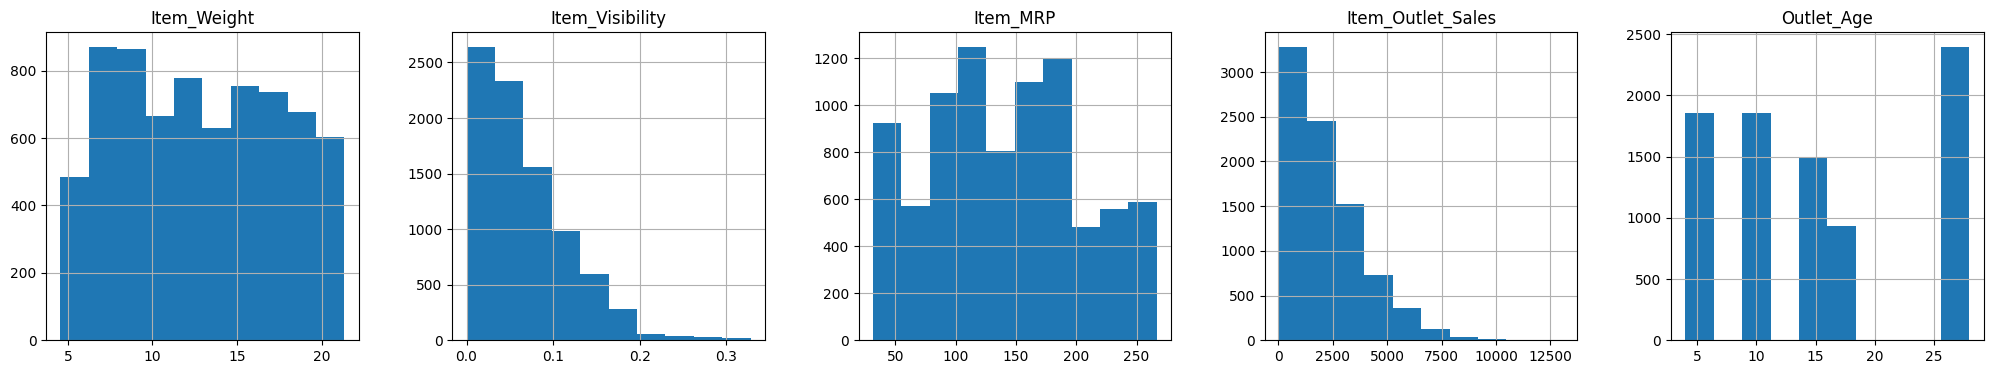

In [ ]:
sales_df.hist(figsize=(25,4), layout=(1,5))
plt.show()

/tmp/ipykernel_804/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])
/tmp/ipykernel_804/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])
/tmp/ipykernel_804/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])
/tmp/ipykernel_804/1984969689.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot

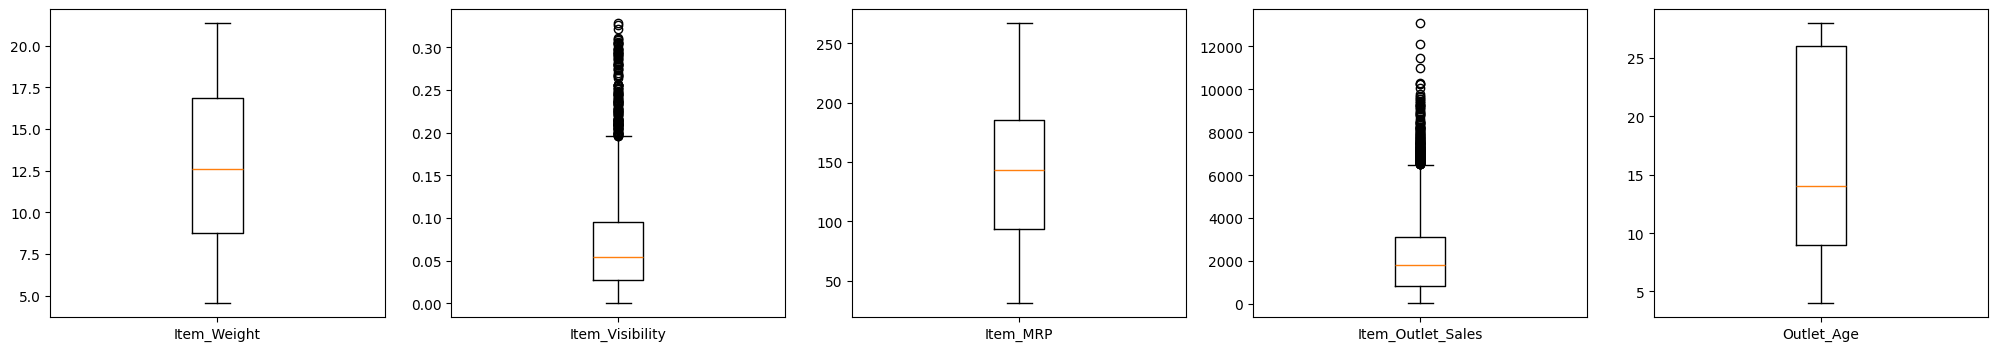

In [ ]:
fig, axes = plt.subplots(1,5, figsize=(25,4))
axes = axes.ravel()
for col, ax in zip(sales_df[num_cols], axes):
  ax.boxplot(sales_df[col].dropna(), labels=[f'{col}'])

**Análisis univariado de variables categóricas**

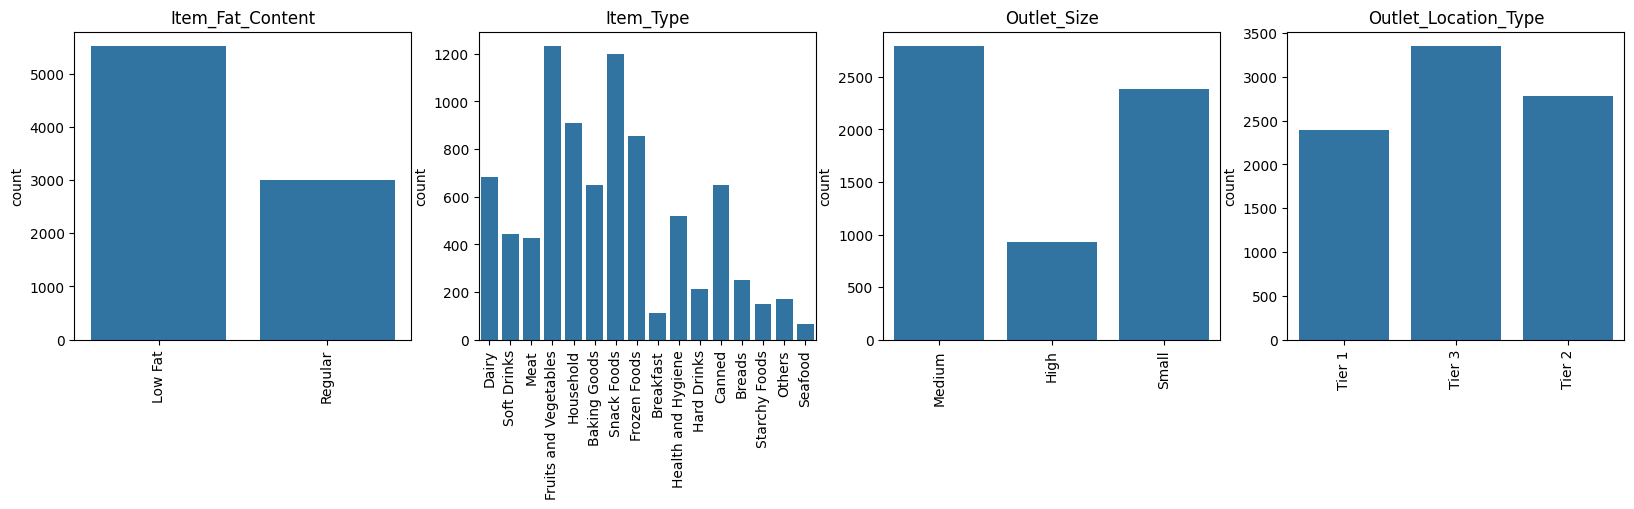

In [ ]:
fig, axes = plt.subplots(1,4, figsize=(20,4))
axes = axes.ravel()
for col, ax in zip(sales_df[cat_cols], axes):
  sns.countplot(x=sales_df[col], ax=ax)
  ax.set(title=f'{col}', xlabel=None)
  ax.tick_params(axis='x',rotation=90)

En `Ite_Fat_Content` hay categorías expresadas de diferente forma:
*   Low Fat = low fat = LF
*   Regular = reg

Se unifica, para sólo dejar dos valores: Low Fat y Regular



In [ ]:
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].apply(lambda x: 'Low Fat' if x == 'low fat' or x == 'LF' else x)
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].apply(lambda x: 'Regular' if x == 'reg' else x)

<Axes: xlabel='Item_Fat_Content', ylabel='count'>

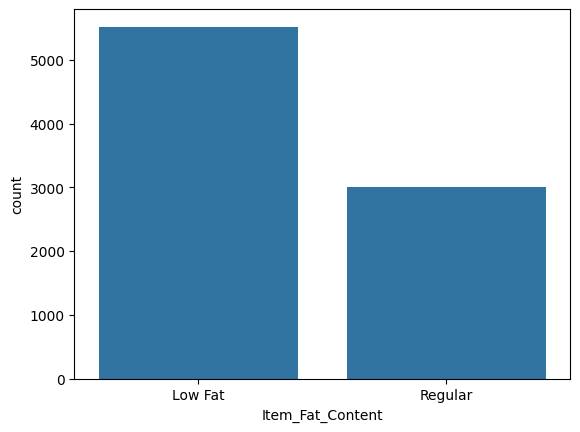

In [ ]:
sns.countplot(x=sales_df['Item_Fat_Content'])

**Análisis bivariado**

<Axes: >

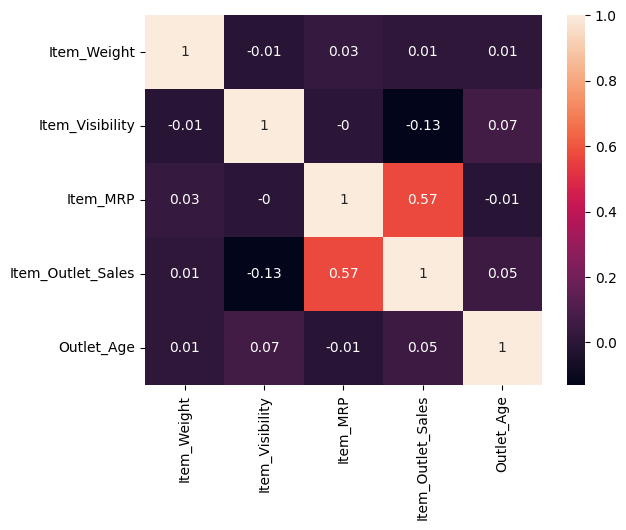

In [ ]:
sns.heatmap(round(sales_df.corr(numeric_only=True),2), annot = True)

Del gráfico anterior, parece que solo la variable independiente `Item_MRP` tiene una relación lineal moderada con la variable dependiente `Item_Outlet_Sales`. Se verifica con diagramas de dispersión.

<Axes: xlabel='Item_MRP', ylabel='Item_Outlet_Sales'>

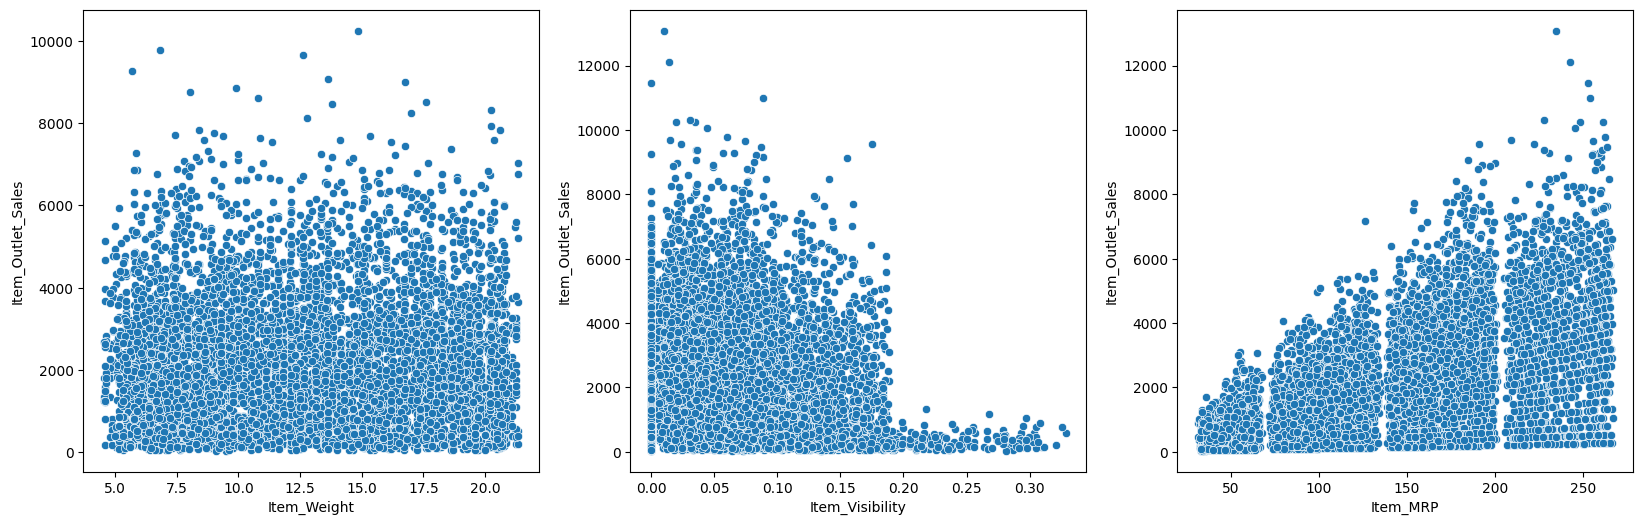

In [ ]:
fig, axes = plt.subplots(1, 3, figsize = (20, 6))
sns.scatterplot(x='Item_Weight', y='Item_Outlet_Sales', data=sales_df, ax=axes[0])
sns.scatterplot(x='Item_Visibility', y='Item_Outlet_Sales', data=sales_df, ax=axes[1])
sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=sales_df, ax=axes[2])

Se crea una nueva característica `Outlet_Age` que indica la antigüedad del outlet.

In [ ]:
from datetime import date

# Solo calcula y elimina si la columna existe (evita errores si ejecutas la celda dos veces)
if 'Outlet_Establishment_Year' in sales_df.columns:
    sales_df['Outlet_Age'] = date.today().year - sales_df['Outlet_Establishment_Year']
    sales_df.drop('Outlet_Establishment_Year', axis=1, inplace=True)
elif 'Outlet_Establishment_year' in sales_df.columns:  # Por si la 'y' final es minúscula
    sales_df['Outlet_Age'] = date.today().year - sales_df['Outlet_Establishment_year']
    sales_df.drop('Outlet_Establishment_year', axis=1, inplace=True)

# Actualizar la separación de variables (X e y)
X = sales_df.drop('Item_Outlet_Sales', axis=1)
y = sales_df['Item_Outlet_Sales']

num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()

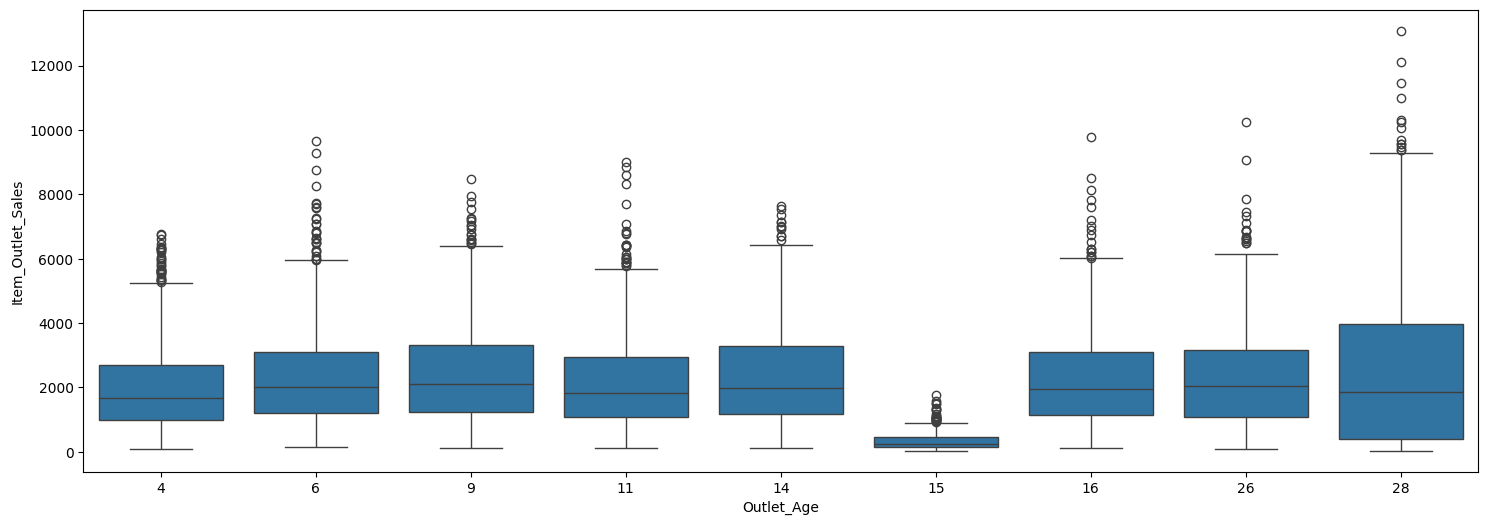

In [ ]:
fig = plt.figure(figsize = (18, 6))
sns.boxplot(x = 'Outlet_Age', y = 'Item_Outlet_Sales', data = sales_df);

**INCIO MODELO MACHINE LEARNING**

INGENIERIA DE CARACTERISTICAS

Se especifican cuales seran las variables de entrada 'X' (Caracteristica) y cual sera la varible predictora 'y' (variable salida o
tambien Objetivo)

In [ ]:
# Se separan las variables del dataframe: en X quedan los predictores y en y la variable de respuesta o salida (Item_Outlet_Sales).
X = sales_df.drop('Item_Outlet_Sales', axis = 1) #variables de entrada - Caracteristica
y = sales_df['Item_Outlet_Sales'] #variable salida -variable predictora - Objetivo

**PARTICION DEL CONJUNTO DE DATOS**

In [ ]:
# Se divide el conjunto en entrenamiento y prueba (80:20)
#80% conjunto de entrenamiento(train)
#20% para el conjunto de prueba (test)

from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X,#variable entrada
                                                y,#variable salida o predictora
                                                train_size=0.8, # tama;o conjunto entrenamiento
                                                random_state=1) #para mantener mismo conjunto de datos

PROCESAMIENTO

**CANALIZACION (PIPELINE)**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Separar datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Pipeline para variables numéricas: Imputación con la mediana y Escalado
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

# Pipeline para variables categóricas: Imputación con el valor más frecuente y OneHotEncoding
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combinar preprocesamiento
preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

# Crear el pipeline final integrando Random Forest
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42))
])

In [ ]:
# Esto no es necesario, pero lo incluyo para que se visualicen los cambios que produce el pipeline "preprocessing" creado anteriormente
# Nótese que Xtrain queda con 27 columnas después del procesamiento, es decir, se utilizarán 27 predictores en el modelo (4 numéricos y 23 categóricos)

Xtrain_prepared = preprocessor.fit_transform(X_train)
Xtrain_prepared_df = pd.DataFrame(Xtrain_prepared, columns=preprocessor.get_feature_names_out(), index=X_train.index)
Xtrain_prepared_df

,num__Item_Weight,num__Item_Visibility,num__Item_MRP,num__Outlet_Age,cat__Item_Fat_Content_Low Fat,cat__Item_Fat_Content_Regular,cat__Item_Type_Baking Goods,cat__Item_Type_Breads,cat__Item_Type_Breakfast,cat__Item_Type_Canned,...,cat__Outlet_Size_High,cat__Outlet_Size_Medium,cat__Outlet_Size_Small,cat__Outlet_Location_Type_Tier 1,cat__Outlet_Location_Type_Tier 2,cat__Outlet_Location_Type_Tier 3,cat__Outlet_Type_Grocery Store,cat__Outlet_Type_Supermarket Type1,cat__Outlet_Type_Supermarket Type2,cat__Outlet_Type_Supermarket Type3
549,0.294433,0.107207,0.594464,0.416667,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
7757,0.800536,0.144563,0.591057,0.291667,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
764,0.776719,0.231802,0.341387,0.500000,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
6867,0.224472,0.090883,0.043819,0.291667,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2716,0.493897,0.417880,0.527478,0.500000,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,0.288181,0.871963,0.457956,0.458333,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
5191,0.657636,0.358032,0.188359,0.083333,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
5390,0.776719,0.057686,0.874662,0.291667,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
860,0.940458,0.165543,0.367815,0.083333,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


**APLICA PREPROCESAMIENTO ANTERIOR PARA EL**

**ENTRENAMIENTO DEL MODELO REGRESION LINEAL**

In [ ]:
# Se crea el pipeline para la predicción, que incluye el de procesamiento creado anteriormente y la regresión lineal

#CREA PIPELINE
lr_model = make_pipeline(preprocessor, LinearRegression())
    #PREPROCESING, procesa los datos (relleno de nulos, escalado (minMaxScaler), codificacion (OneHOtEnconder))
    #LinearRegresion, aplica modelo de regresion lineal a los datos ya entrenados

#ENTRENA Y AJUSTA TODO EL PIPELINE CON LOS DATOS DE ENTRENAMIENTO
lr_model.fit(Xtrain, ytrain)
    #primero transforma Xtrain con el preprocesador
    #luego entrena el modelo de LinearRegresion() con las variables transformadas y la variable objetivo ytrain

#APLICA PIPELINE A LOS DATOS DE PRUEBA
predictions = lr_model.predict(Xtest)
  #primero transforma con el mismo preprocesador (usando los parametros aprendidos en fit)
  #despues realiza predicciones con el modelo entrenado

import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Calcula el RMSE sacando la raíz cuadrada del error cuadrático medio
rmse = np.sqrt(mean_squared_error(ytest, predictions))
print('The Root Mean Square Error (RMSE) is:', rmse)
print('The R square (R2) is:', r2_score(ytest, predictions))

The Root Mean Square Error (RMSE) is: 1144.3827848578726
The R square (R2) is: 0.5582080574611581


RMSE = 1144.38, significa que el modelo se equivoca por unas 1144.38 unidades.

r2 =0.558, significa que elmodelo explcia el 55.8% de la variabilidad de los datos, el 42% restante, no lo puede explicar (puede deberse al ruido, datos faltantes, variables importantes no incluidas), o hacer uso de otro tipo de transformaciones de variables.

El resultado obtenido por el modelo de regresion lineal no es excelente, debido a que esta haciendo predicciones con un error moderado y explica poco mas de la mitad del comportamiento de la variable objetivo

Lo que seguiría es hacer más transformaciones para mejorar el resultado. Por ejemplo:

* Aplicar una transformación (log, box-cox,...) para hacer que la distribución de `Item_Visibility` tenga una forma más normal, porque está sesgada.

* Usar StandarScaler o RobustScaler en lugar de MinMax.
* Aplicar OrdinalEncoder a algunas categóricas, en lugar de OneHotEncoder.

In [ ]:
# Se puede tener acceso a los pasos ejecutados en el pipeline
lr_model.named_steps

{'columntransformer': ColumnTransformer(transformers=[('num',
                                  Pipeline(steps=[('imputer',
                                                   SimpleImputer(strategy='median')),
                                                  ('scaler', MinMaxScaler())]),
                                  ['Item_Weight', 'Item_Visibility', 'Item_MRP',
                                   'Outlet_Age']),
                                 ('cat',
                                  Pipeline(steps=[('imputer',
                                                   SimpleImputer(strategy='most_frequent')),
                                                  ('encoder',
                                                   OneHotEncoder(handle_unknown='ignore',
                                                                 sparse_output=False))]),
                                  ['Item_Fat_Content', 'Item_Type',
                                   'Outlet_Size', 'Outlet_Location_Type'

In [ ]:
# Una vez ubicado en un paso, por ejemplo en la regresión lineal ('linearregression'), se puede tener acceso a sus atributos
# Para mostrar la intercepción o beta_0
lr_model.named_steps['linearregression'].intercept_

np.float64(1223.6245185115154)

In [ ]:
# Para mostrar los coeficientes: beta_1, beta_2, ... beta_n
# En este caso se obtienen 27 coeficientes, uno por predictor
lr_model.named_steps['linearregression'].coef_

array([ 2.86235526e+01, -9.70961234e+01,  3.67893686e+03, -8.83748486e+02,
       -1.80465279e+01,  1.80465279e+01, -2.55284949e+00,  6.54343360e+00,
       -1.82737730e+01,  3.21345570e+01, -1.03010984e+02, -4.16019857e+01,
        3.55265347e+01, -2.64456954e+01,  8.44600961e+00, -6.50726860e+01,
       -3.64607615e+01, -3.86169577e+01,  2.80687875e+02,  1.25553353e+01,
       -7.72939453e+01,  3.34358929e+01,  5.28778324e+02, -3.10904359e+02,
       -2.17873965e+02,  1.99164832e+02, -3.01069991e+00, -1.96154132e+02,
       -1.65635485e+03, -1.46664998e+02, -4.12923345e+02,  2.21594319e+03])

In [ ]:
# Para mostrar los transformadores ejecutados
lr_model.named_steps['columntransformer']

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', MinMaxScaler())]),
                                 ['Item_Weight', 'Item_Visibility', 'Item_MRP',
                                  'Outlet_Age']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['Item_Fat_Content', 'Item_Type',
                                  'Outlet_Size', 'Outlet_Location_Type',
                                  'Outlet_Type'])])

In [ ]:
# Para tener acceso a un transformador en particular
lr_model.named_steps['columntransformer'].named_transformers_['num']

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', MinMaxScaler())])

In [ ]:
lr_model.named_steps['columntransformer'].named_transformers_['num'].named_steps['scaler'].min_

array([-0.27121167,  0.        , -0.13281075, -0.16666667])

In [ ]:
# Entrenar el modelo
model_pipeline.fit(X_train, y_train)

# Predecir sobre el conjunto de prueba
y_pred = model_pipeline.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

Root Mean Squared Error (RMSE): 1042.14
R2 Score: 0.6004


### ¿Por qué la Regresión Lineal no alcanza el 70% ($R^2$) en este dataset?

* **Relaciones no lineales:** Las características y las ventas reales no siguen una línea recta estricta.
* **Falta de interacciones:** El modelo lineal estándar no captura de forma nativa cómo interactúan las variables entre sí.
* **Alta varianza y ruido:** El comportamiento minorista incluye fluctuaciones extremas y valores atípicos difíciles de ajustar con una simple recta.
* **Superioridad de modelos basados en árboles:** Este tipo de problemas de ventas se beneficia más de algoritmos capaces de segmentar el espacio de características de forma no lineal (como Random Forest).